# Notebook 04 — Machine Learning for Credit Risk

**FIN 4600 · Lab 3 · Financial Data Analytics**

Duran, *Financial Services Technology* (3rd ed.), **Chapter 6 — Data Analytics**

---

Credit scoring is the oldest and most successful application of statistical
learning in finance. It also has a property that market prediction does not:
**the signal is real**. Applicants with no checking account and a history of
missed payments really do default more often. That makes it the right place to
learn the machinery, because when something does not work you can be
reasonably confident the problem is your code rather than the universe.

**The data.** The Statlog (German Credit) dataset — 1,000 loan applications
from a German bank, 20 attributes each, with a known good/bad outcome. It has
been a teaching and benchmarking standard since 1994.

**What you will learn**

1. Exploring a categorical-heavy dataset
2. Fair lending: which variables you are legally forbidden to use
3. `ColumnTransformer` and `Pipeline` — encoding without leakage
4. Logistic regression, and reading coefficients as odds ratios
5. Tree-based models: decision tree, random forest, gradient boosting
6. Why accuracy is the wrong metric, and what to use instead
7. Cross-validation
8. Choosing a cut-off from expected profit, not from 0.5

## 0. Setup

In [40]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_repo_root(start=None):
    """Return the repository root — the folder that contains data/sp500_prices.csv."""
    here = Path(start or Path.cwd()).resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "sp500_prices.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. In VS Code use File > Open Folder "
        "and open the mtu4600-lab3-analytics folder itself, then re-run."
    )


REPO = find_repo_root()
DATA = REPO / "data"
plt.style.use(REPO / "fin4600.mplstyle")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

RANDOM_STATE = 42  # fix the seed so everyone in the class gets the same numbers

In [41]:
credit = pd.read_csv(DATA / "german_credit.csv")

print("Shape:", credit.shape)
print(f"Default rate: {credit['default'].mean():.1%}")
credit.head()

Shape: (1000, 22)
Default rate: 30.0%


,applicant_id,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,default
0,A0001,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,4,real estate,67,none,own,2,skilled employee/official,1,yes,yes,0
1,A0002,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee/official,1,no,yes,1
2,A0003,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,3,real estate,49,none,own,1,unskilled - resident,2,no,yes,0
3,A0004,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,4,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,0
4,A0005,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,4,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,1


## 1. What is in the file?

In [42]:
credit.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   applicant_id             1000 non-null   str  
 1   status                   1000 non-null   str  
 2   duration                 1000 non-null   int64
 3   credit_history           1000 non-null   str  
 4   purpose                  1000 non-null   str  
 5   amount                   1000 non-null   int64
 6   savings                  1000 non-null   str  
 7   employment_duration      1000 non-null   str  
 8   installment_rate         1000 non-null   int64
 9   personal_status_sex      1000 non-null   str  
 10  other_debtors            1000 non-null   str  
 11  present_residence        1000 non-null   int64
 12  property                 1000 non-null   str  
 13  age                      1000 non-null   int64
 14  other_installment_plans  1000 non-null   str  
 15  housing         

In [43]:
numeric_columns = credit.select_dtypes(include="number").columns.drop("default").tolist()
categorical_columns = credit.select_dtypes(exclude="number").columns.drop("applicant_id").tolist()

print(f"{len(numeric_columns)} numeric features:")
print("   ", ", ".join(numeric_columns))
print(f"\n{len(categorical_columns)} categorical features:")
print("   ", ", ".join(categorical_columns))

7 numeric features:
    duration, amount, installment_rate, present_residence, age, number_credits, people_liable

13 categorical features:
    status, credit_history, purpose, savings, employment_duration, personal_status_sex, other_debtors, property, other_installment_plans, housing, job, telephone, foreign_worker


In [44]:
credit[numeric_columns].describe().round(1)

,duration,amount,installment_rate,present_residence,age,number_credits,people_liable
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.9,3271.3,3.0,2.8,35.5,1.4,1.2
std,12.1,2822.7,1.1,1.1,11.4,0.6,0.4
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0
75%,24.0,3972.2,4.0,4.0,42.0,2.0,1.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0


## 2. Which variables look like they matter?

Before fitting anything, look at the default rate within each category. This
is the credit analyst's version of exploratory data analysis, and it is often
where most of the insight comes from.

In [45]:
def default_rate_by(column: str) -> pd.DataFrame:
    table = credit.groupby(column).agg(
        applications=("default", "size"),
        default_rate=("default", "mean"),
    )
    table["default_rate"] = (table["default_rate"] * 100).round(1)
    return table.sort_values("default_rate", ascending=False)


print("Checking account status\n", default_rate_by("status").to_string(), "\n")
print("Credit history\n", default_rate_by("credit_history").to_string())

Checking account status
                                             applications  default_rate
status                                                                
... < 100 DM                                         274          49.3
0 <= ... < 200 DM                                    269          39.0
... >= 200 DM / salary for at least 1 year            63          22.2
no checking account                                  394          11.7 

Credit history
                                              applications  default_rate
credit_history                                                         
no credits taken/all credits paid back duly            40          62.5
all credits at this bank paid back duly                49          57.1
existing credits paid back duly till now              530          31.9
delay in paying off in the past                        88          31.8
critical account/other credits existing               293          17.1


Read those tables carefully — they contain the whole story of this dataset.

Applicants with **no checking account at all** default 11.7% of the time,
while those holding one with a balance under 100 DM default 49.3% of the
time. The counter-intuitive result — no account is *safer* — is real, and it
is the kind of thing that makes credit modelling interesting: having no
account at this bank often means banking elsewhere, which is not a risk
signal.

Credit history is stranger still. "No credits taken / all paid back duly"
shows the **highest** default rate. A borrower with no track record is not
safe — they are unmeasured. Thin-file applicants are a genuine industry
problem.

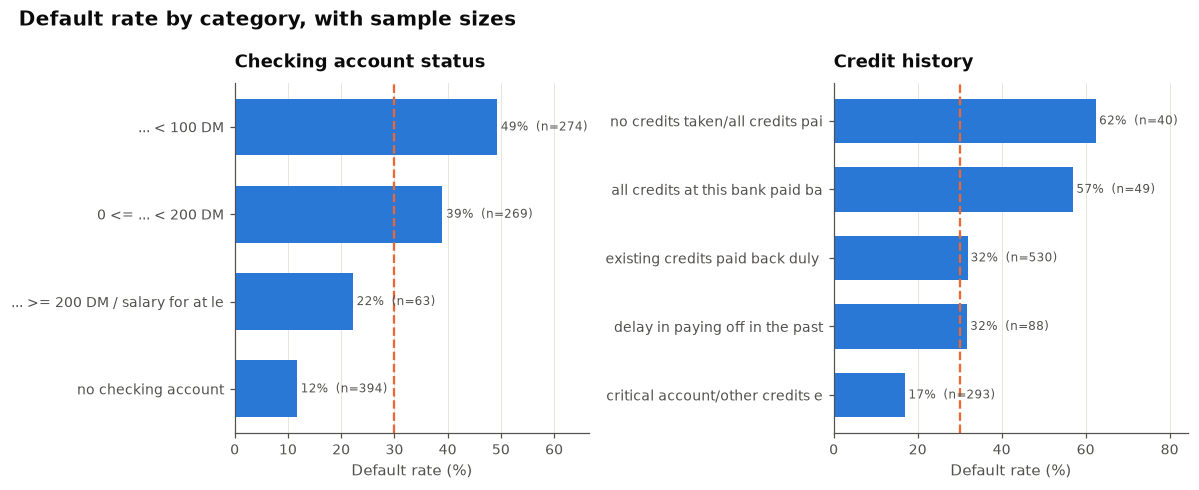

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, column, title in [
    (axes[0], "status", "Checking account status"),
    (axes[1], "credit_history", "Credit history"),
]:
    table = default_rate_by(column).sort_values("default_rate")
    labels = [str(i)[:32] for i in table.index]
    ax.barh(labels, table["default_rate"], color="#2a78d6", height=0.65)
    ax.axvline(credit["default"].mean() * 100, color="#eb6834", linewidth=1.5, linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Default rate (%)")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    for y, (rate, n) in enumerate(zip(table["default_rate"], table["applications"])):
        ax.text(rate + 0.7, y, f"{rate:.0f}%  (n={n})", va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, table["default_rate"].max() * 1.35)

axes[0].annotate("portfolio average 30%", xy=(30, -0.55), fontsize=8,
                 color="#eb6834", ha="center")
fig.suptitle("Default rate by category, with sample sizes", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Note the `n=` labels. The two worst credit-history categories rest on 40 and
49 applications respectively, so those rates carry wide error bars. A high
default rate on a handful of applications is not a finding. Always show the
denominator.

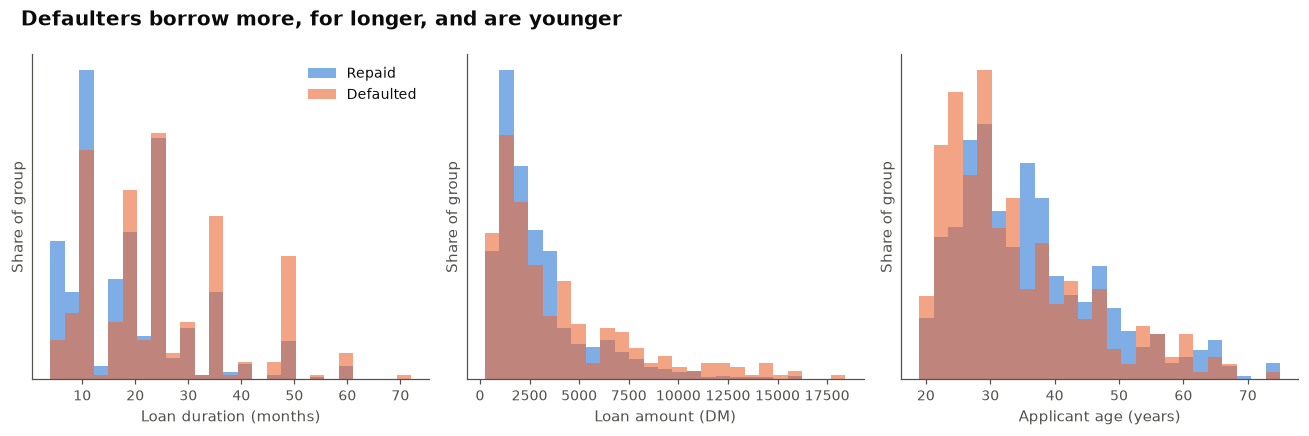

         duration  amount   age
default                        
0            19.2  2985.5  36.2
1            24.9  3938.1  34.0


In [47]:
# Continuous variables: do defaulters borrow more, for longer?
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column, label in [
    (axes[0], "duration", "Loan duration (months)"),
    (axes[1], "amount", "Loan amount (DM)"),
    (axes[2], "age", "Applicant age (years)"),
]:
    repaid = credit.loc[credit["default"] == 0, column]
    defaulted = credit.loc[credit["default"] == 1, column]
    bins = np.histogram_bin_edges(credit[column], bins=25)
    ax.hist(repaid, bins=bins, density=True, alpha=0.6, color="#2a78d6", label="Repaid")
    ax.hist(defaulted, bins=bins, density=True, alpha=0.6, color="#eb6834", label="Defaulted")
    ax.set_xlabel(label)
    ax.set_ylabel("Share of group")
    ax.set_yticks([])

axes[0].legend()
fig.suptitle("Defaulters borrow more, for longer, and are younger", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

print(credit.groupby("default")[["duration", "amount", "age"]].mean().round(1).to_string())

## 3. Fair lending — the variables you must not use

This section is not optional and it is not a footnote. It is the part of
credit modelling most likely to end a career.

In the United States, the **Equal Credit Opportunity Act** (ECOA) and its
implementing **Regulation B** prohibit discrimination in any aspect of a
credit transaction on the basis of race, colour, religion, national origin,
**sex**, marital status, or age (for applicants old enough to contract), or
because income derives from public assistance.

This dataset contains three variables that are legally radioactive:

In [48]:
print(credit["personal_status_sex"].value_counts().to_string())
print()
print(credit["foreign_worker"].value_counts().to_string())
print(f"\nAge range: {credit['age'].min()} to {credit['age'].max()}")

personal_status_sex
male : single                          548
female : divorced/separated/married    310
male : married/widowed                  92
male : divorced/separated               50

foreign_worker
yes    963
no      37

Age range: 19 to 75


In [49]:
# What do those variables look like in the outcome data?
for column in ["personal_status_sex", "foreign_worker"]:
    print(f"\n{column}")
    print(default_rate_by(column).to_string())


personal_status_sex
                                     applications  default_rate
personal_status_sex                                            
male : divorced/separated                      50          40.0
female : divorced/separated/married           310          35.2
male : married/widowed                         92          27.2
male : single                                 548          26.6

foreign_worker
                applications  default_rate
foreign_worker                            
yes                      963          30.7
no                        37          10.8


There *are* differences in the raw default rates. That is exactly the trap.
A variable being statistically predictive does not make it lawful to use, and
under ECOA the intent behind the model is irrelevant — what matters is the
effect.

Two further points that are easy to miss:

- **Dropping the variable is not sufficient.** A model can reconstruct a
  protected characteristic from correlated variables — this is *proxy
  discrimination*, and it is the reason fair-lending testing looks at
  outcomes, not just inputs. Postal code standing in for race is the classic
  US example.
- **Disparate impact is actionable without disparate treatment.** A
  facially neutral rule that produces a significant adverse effect on a
  protected class can violate the Act even if nobody intended it.

For this lab we drop the two most obviously protected variables. `age` is a
harder call: it is protected under ECOA for applicants of legal contracting
age, but it is also a legitimate underwriting input in some jurisdictions
and product types. We keep it here and flag it, which is what an honest model
card would do.

In [50]:
PROTECTED = ["personal_status_sex", "foreign_worker"]

credit_model = credit.drop(columns=["applicant_id"] + PROTECTED)
categorical_columns = [c for c in categorical_columns if c not in PROTECTED]

print("Dropped from the model:", ", ".join(PROTECTED))
print("Retained with a documented caveat: age")
print(f"\nFeatures remaining: {credit_model.shape[1] - 1}")

Dropped from the model: personal_status_sex, foreign_worker
Retained with a documented caveat: age

Features remaining: 18


### Exercise 1

Train the model below twice — once as written, and once with
`personal_status_sex` added back in. Compare the ROC-AUC. If including the
protected variable improves the model, does that change your view about
whether it should be used? Write two or three sentences.

## 4. Splitting the data

Unlike the market panel in Notebook 03, these are cross-sectional
observations with no time ordering, so a **random** split is correct here.

We stratify on the target so that the training and test sets have the same
30% default rate. Without stratification, a small test set can drift to 25%
or 35% by chance and every metric moves with it.

In [51]:
from sklearn.model_selection import train_test_split

X = credit_model.drop(columns="default")
y = credit_model["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {len(X_train)} applications, {y_train.mean():.1%} default")
print(f"Test set:     {len(X_test)} applications, {y_test.mean():.1%} default")

Training set: 750 applications, 30.0% default
Test set:     250 applications, 30.0% default


## 5. Preprocessing as part of the model

The categorical columns hold text. Models need numbers. **One-hot encoding**
turns a column with $k$ categories into $k$ indicator columns.

The important design choice is to put the encoder *inside* a `Pipeline`.
Then `fit` on training data learns the categories and the scaling, and
`predict` on test data applies them — so the leak we had to be careful about
by hand in Notebook 03 becomes structurally impossible.

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        (
            "categorical",
            # handle_unknown="ignore" stops the model crashing when a category
            # appears in production that was not in the training data.
            OneHotEncoder(handle_unknown="ignore", drop="first"),
            categorical_columns,
        ),
    ]
)

preprocessor.fit(X_train)
encoded_names = preprocessor.get_feature_names_out()
print(f"{X_train.shape[1]} original columns became {len(encoded_names)} model columns")
print("\nFirst twelve:")
for name in encoded_names[:12]:
    print("   ", name)

18 original columns became 44 model columns

First twelve:
    numeric__duration
    numeric__amount
    numeric__installment_rate
    numeric__present_residence
    numeric__age
    numeric__number_credits
    numeric__people_liable
    categorical__status_... >= 200 DM / salary for at least 1 year
    categorical__status_0 <= ... < 200 DM
    categorical__status_no checking account
    categorical__credit_history_critical account/other credits existing
    categorical__credit_history_delay in paying off in the past


## 6. Logistic regression

The workhorse of credit scoring, and still the model most likely to be in
production at a regulated lender — because you can explain it. Under the
Fair Credit Reporting Act a declined applicant is entitled to the specific
reasons for the decision, and "the gradient boosting ensemble said no" is not
a reason.

Logistic regression models the log-odds of default as a linear function of
the features:

$$\ln\!\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

In [53]:
logistic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['status','duration','credit_history',...,'job','people_liable', 'telephone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

Look hard at that last line. The model is barely beating the strategy of
approving every single application. Accuracy is a terrible metric on
imbalanced data, and credit data is always imbalanced. We need better
measures — and we need them before we believe anything.

In [54]:
from sklearn.metrics import roc_auc_score

# Model as written (personal_status_sex left out)
auc_without = roc_auc_score(y_test, logistic.predict_proba(X_test)[:, 1])

# Same model, with personal_status_sex added back in
X2 = credit.drop(columns=["applicant_id", "foreign_worker", "default"])
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
preprocessor2 = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore", drop="first"),
         categorical_columns + ["personal_status_sex"]),
    ]
)
logistic2 = Pipeline(
    steps=[
        ("preprocess", preprocessor2),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
logistic2.fit(X2_train, y2_train)
auc_with = roc_auc_score(y2_test, logistic2.predict_proba(X2_test)[:, 1])

print(f"ROC-AUC without personal_status_sex: {auc_without:.3f}")
print(f"ROC-AUC with personal_status_sex:    {auc_with:.3f}")

ROC-AUC without personal_status_sex: 0.800
ROC-AUC with personal_status_sex:    0.799


**Exercise 1 answer:** Adding personal_status_sex back in doesn't help. ROC-AUC is 0.800 without it and 0.799 with it, so it adds essentially nothing. That makes me more confident it should stay out, since there's no real accuracy gain to justify the legal risk. And even if it had improved the model, I'd still leave it out, because under ECOA a variable being predictive isn't a lawful reason to use it.

## 7. Evaluating a classifier properly

The **confusion matrix** is the foundation. Every other metric is a ratio
computed from its four cells.

In [55]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)

y_pred = logistic.predict(X_test)
y_proba = logistic.predict_proba(X_test)[:, 1]

matrix = confusion_matrix(y_test, y_pred)
true_negative, false_positive, false_negative, true_positive = matrix.ravel()

print("                        Predicted repay    Predicted default")
print(f"Actually repaid  {true_negative:>16}  {false_positive:>18}")
print(f"Actually defaulted{false_negative:>15}  {true_positive:>18}")
print()
print(f"The {false_negative} bad loans we approved are the expensive mistake.")
print(f"The {false_positive} good loans we declined cost us foregone margin.")

                        Predicted repay    Predicted default
Actually repaid               154                  21
Actually defaulted             35                  40

The 35 bad loans we approved are the expensive mistake.
The 21 good loans we declined cost us foregone margin.


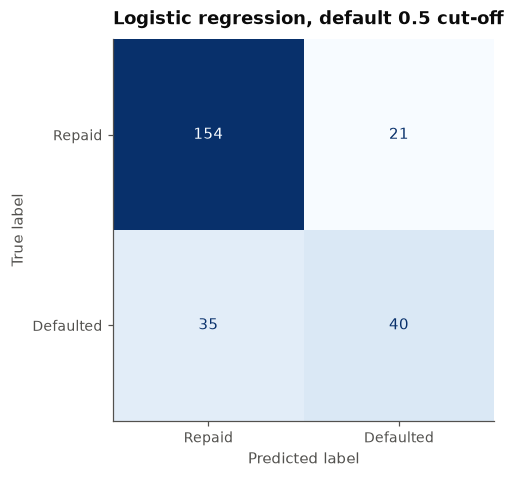

In [56]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=matrix, display_labels=["Repaid", "Defaulted"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Logistic regression, default 0.5 cut-off")
ax.grid(False)
plt.show()

In [57]:
print(classification_report(y_test, y_pred, target_names=["Repaid", "Defaulted"]))

              precision    recall  f1-score   support

      Repaid       0.81      0.88      0.85       175
   Defaulted       0.66      0.53      0.59        75

    accuracy                           0.78       250
   macro avg       0.74      0.71      0.72       250
weighted avg       0.77      0.78      0.77       250



The vocabulary, in lending terms:

| Metric | Formula | What it means to a lender |
|---|---|---|
| **Precision** (defaulted) | TP / (TP + FP) | of the applications we declined for risk, how many would really have gone bad |
| **Recall** (defaulted) | TP / (TP + FN) | of the loans that would have gone bad, how many did we catch |
| **F1** | harmonic mean | a single number when you must have one |

Recall on the defaulted class is the number that matters most here, and it is
low. The model is missing most of the bad loans. We will fix that in section
10 — not by changing the model, but by changing the cut-off.

### ROC-AUC: the threshold-free measure

The ROC curve traces the trade-off between catching bad loans (true positive
rate) and wrongly declining good ones (false positive rate) across **every**
possible cut-off. The area under it is the probability that the model gives a
randomly chosen defaulter a higher score than a randomly chosen repayer.

0.5 is a coin flip. In credit scoring, 0.70–0.80 is a usable model and above
0.85 you should check for leakage.

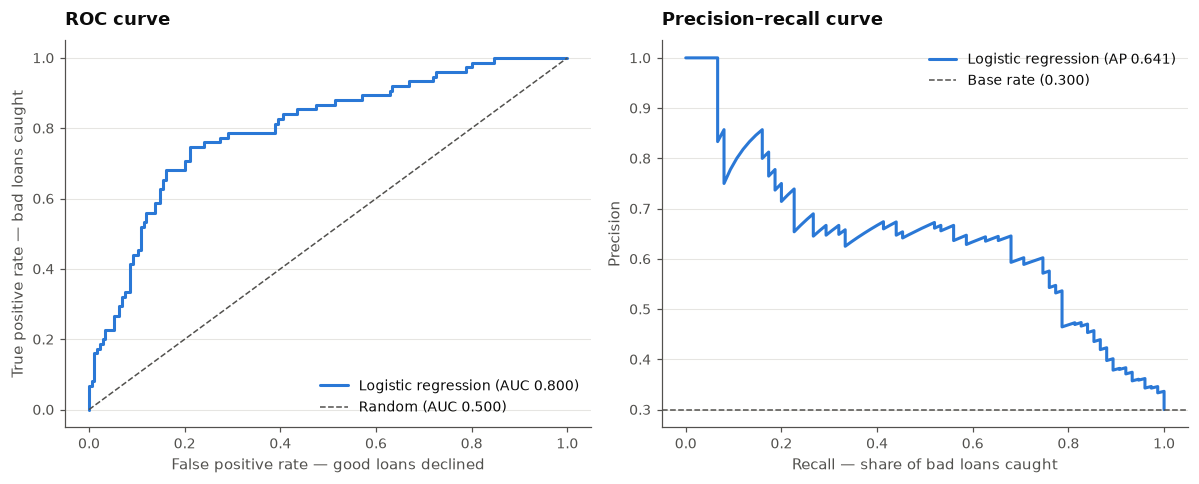

In [58]:
auc = roc_auc_score(y_test, y_proba)
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_proba)

precision, recall, _ = precision_recall_curve(y_test, y_proba)
average_precision = average_precision_score(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(false_positive_rate, true_positive_rate, color="#2a78d6",
             label=f"Logistic regression (AUC {auc:.3f})")
axes[0].plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1,
             label="Random (AUC 0.500)")
axes[0].set_xlabel("False positive rate — good loans declined")
axes[0].set_ylabel("True positive rate — bad loans caught")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right")

axes[1].plot(recall, precision, color="#2a78d6",
             label=f"Logistic regression (AP {average_precision:.3f})")
axes[1].axhline(y_test.mean(), color="#52514e", linestyle="--", linewidth=1,
                label=f"Base rate ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall — share of bad loans caught")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curve")
axes[1].legend(loc="upper right")

fig.tight_layout()
plt.show()

## 8. Reading the coefficients

This is what logistic regression buys you that a forest does not. Exponentiate
a coefficient and you get an **odds ratio**: the multiplicative effect on the
odds of default of a one-unit increase in that feature, holding everything
else fixed.

In [59]:
coefficients = pd.DataFrame(
    {
        "feature": logistic.named_steps["preprocess"].get_feature_names_out(),
        "coefficient": logistic.named_steps["model"].coef_[0],
    }
)
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients["feature"] = (
    coefficients["feature"].str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

print("Increases the odds of default the most:")
print(coefficients.nlargest(8, "coefficient")[["feature", "coefficient", "odds_ratio"]].round(3).to_string(index=False))
print("\nDecreases the odds of default the most:")
print(coefficients.nsmallest(8, "coefficient")[["feature", "coefficient", "odds_ratio"]].round(3).to_string(index=False))

Increases the odds of default the most:
                                                   feature  coefficient  odds_ratio
                                        purpose_retraining        1.076       2.932
                                              housing_rent        0.895       2.448
                              property_unknown/no property        0.662       1.939
                                         purpose_car (new)        0.436       1.546
                                         purpose_education        0.386       1.471
                                               housing_own        0.364       1.439
credit_history_no credits taken/all credits paid back duly        0.351       1.420
                                                  duration        0.329       1.389

Decreases the odds of default the most:
                                               feature  coefficient  odds_ratio
                            status_no checking account       -1.495       0.224
   

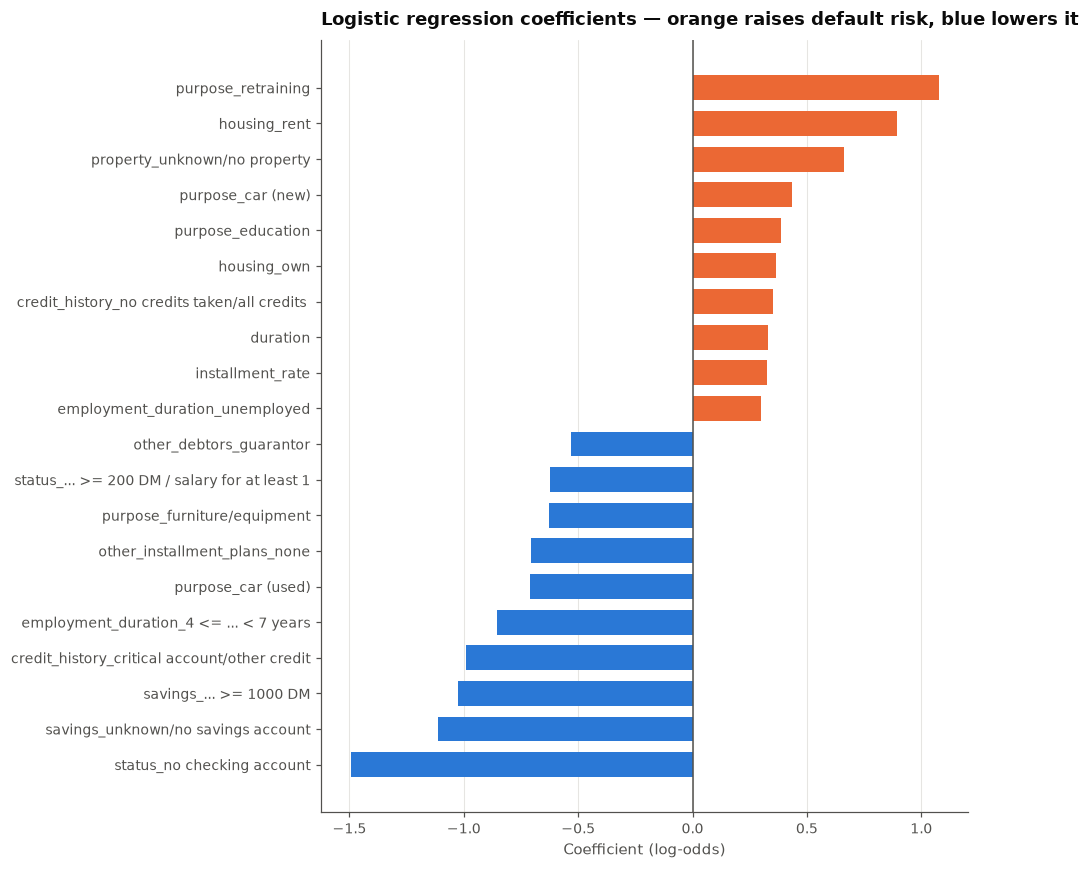

In [60]:
top = pd.concat([coefficients.nlargest(10, "coefficient"), coefficients.nsmallest(10, "coefficient")])
top = top.sort_values("coefficient")

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#eb6834" if c > 0 else "#2a78d6" for c in top["coefficient"]]
ax.barh([f[:44] for f in top["feature"]], top["coefficient"], color=colors, height=0.7)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title("Logistic regression coefficients — orange raises default risk, blue lowers it")
ax.set_xlabel("Coefficient (log-odds)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

The numeric coefficients are on standardised features, so they read as "one
standard deviation more of this". The categorical ones are relative to the
dropped reference category.

A worked example: an odds ratio of 1.8 on a category means applicants in that
category have 1.8 times the odds of defaulting compared with the reference
group, all else equal. That sentence is exactly what goes in an adverse
action notice, which is why this model is still in production everywhere.

## 9. Tree-based models

Trees split the data on one variable at a time, recursively. They capture
interactions and non-linearities that a linear model cannot, and they are
invariant to feature scaling.

In [61]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision tree (depth 4)": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = []
fitted = {}

for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    results.append(
        {
            "model": name,
            "train_accuracy": pipeline.score(X_train, y_train),
            "test_accuracy": pipeline.score(X_test, y_test),
            "test_auc": roc_auc_score(y_test, probabilities),
            "avg_precision": average_precision_score(y_test, probabilities),
        }
    )

results_table = pd.DataFrame(results).set_index("model").round(3)
results_table

,train_accuracy,test_accuracy,test_auc,avg_precision
model,,,,
Logistic regression,0.768,0.776,0.800,0.641
Decision tree (depth 4),0.731,0.688,0.704,0.438
Random forest,0.857,0.752,0.803,0.652
Gradient boosting,0.901,0.768,0.819,0.684


Look at the gap between `train_accuracy` and `test_accuracy`. A random forest
will typically score near-perfectly on the training data and much worse on
the test data. That gap is **overfitting**: the model has memorised the
training applications rather than learned a rule that generalises.

On a dataset with 1,000 rows and this much noise, the elaborate models rarely
beat logistic regression by enough to justify losing explainability. That is
a genuine and slightly unfashionable result, and it is why credit scorecards
still look the way they do.

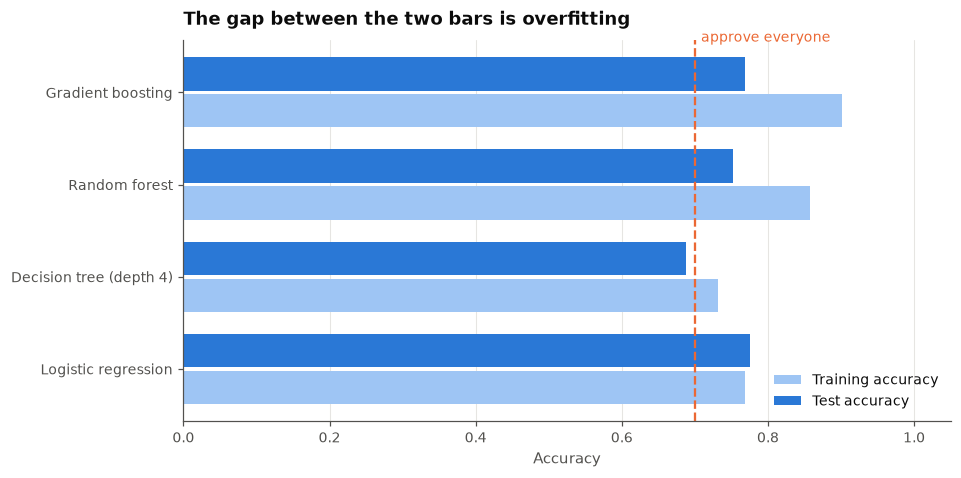

In [62]:
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(results_table))
ax.barh(positions - 0.2, results_table["train_accuracy"], height=0.36,
        color="#9ec5f4", label="Training accuracy")
ax.barh(positions + 0.2, results_table["test_accuracy"], height=0.36,
        color="#2a78d6", label="Test accuracy")
ax.set_yticks(positions, results_table.index)
ax.axvline(1 - y_test.mean(), color="#eb6834", linestyle="--", linewidth=1.5)
ax.annotate("approve everyone", xy=(1 - y_test.mean(), len(results_table) - 0.45),
            xytext=(4, 0), textcoords="offset points", fontsize=9, color="#eb6834")
ax.set_xlabel("Accuracy")
ax.set_xlim(0, 1.05)
ax.set_title("The gap between the two bars is overfitting")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

### Seeing inside a tree

A shallow decision tree is the one machine learning model you can hand to a
credit committee and have them read it.

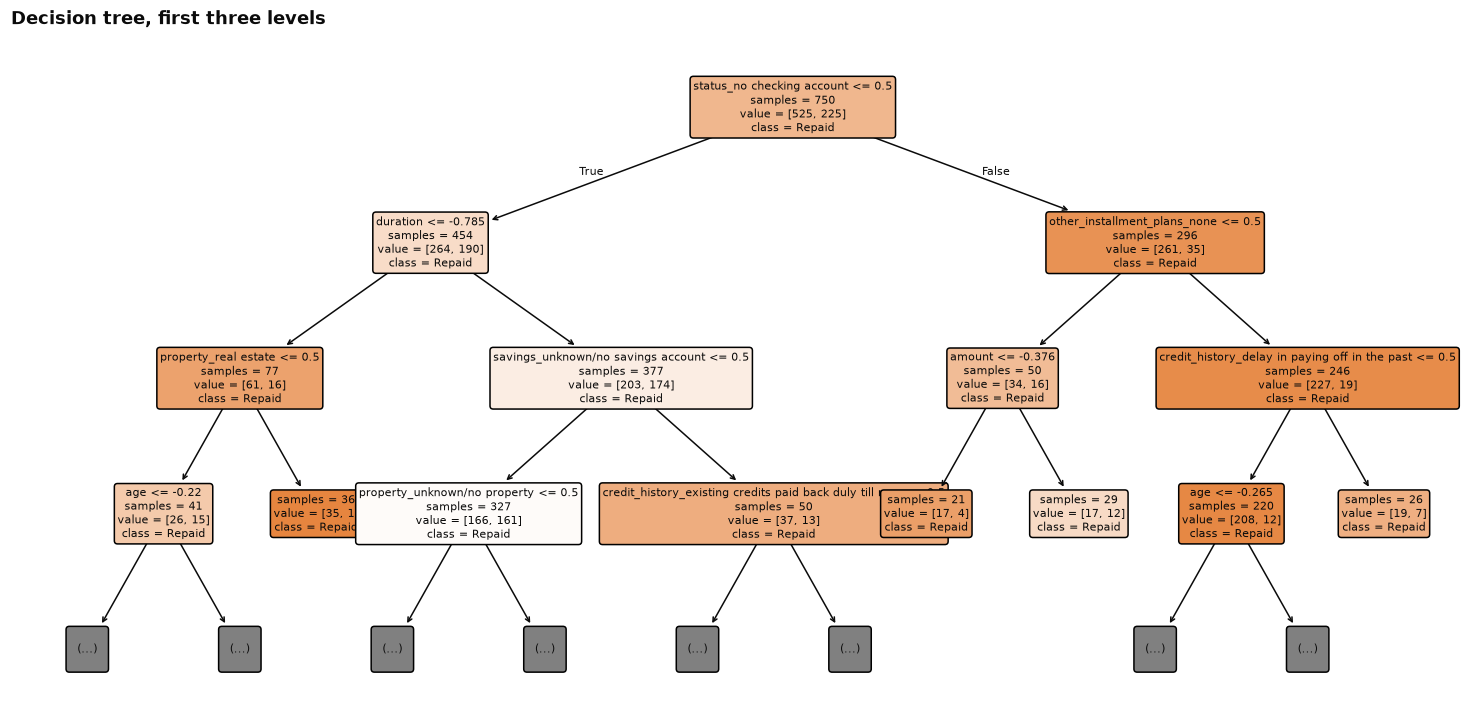

In [63]:
tree_pipeline = fitted["Decision tree (depth 4)"]
tree_feature_names = [
    name.replace("numeric__", "").replace("categorical__", "")
    for name in tree_pipeline.named_steps["preprocess"].get_feature_names_out()
]

fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(
    tree_pipeline.named_steps["model"],
    feature_names=tree_feature_names,
    class_names=["Repaid", "Defaulted"],
    filled=True,
    rounded=True,
    fontsize=7,
    max_depth=3,
    impurity=False,
    ax=ax,
)
ax.set_title("Decision tree, first three levels")
plt.show()

### Which features does the forest rely on?

Built-in tree importances are biased toward high-cardinality features.
**Permutation importance** is the more trustworthy measure: shuffle one
column in the test set and see how much the score falls.

In [64]:
from sklearn.inspection import permutation_importance

forest = fitted["Random forest"]
importance = permutation_importance(
    forest, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
    scoring="roc_auc",
)

importance_table = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "importance": importance.importances_mean,
            "std": importance.importances_std,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print(importance_table.head(10).round(4).to_string(index=False))

                feature  importance    std
                 status      0.1134 0.0267
               duration      0.0262 0.0127
                 amount      0.0236 0.0097
                purpose      0.0134 0.0056
         credit_history      0.0116 0.0095
                    age      0.0109 0.0036
       installment_rate      0.0064 0.0039
other_installment_plans      0.0062 0.0032
                savings      0.0049 0.0077
          other_debtors      0.0042 0.0013


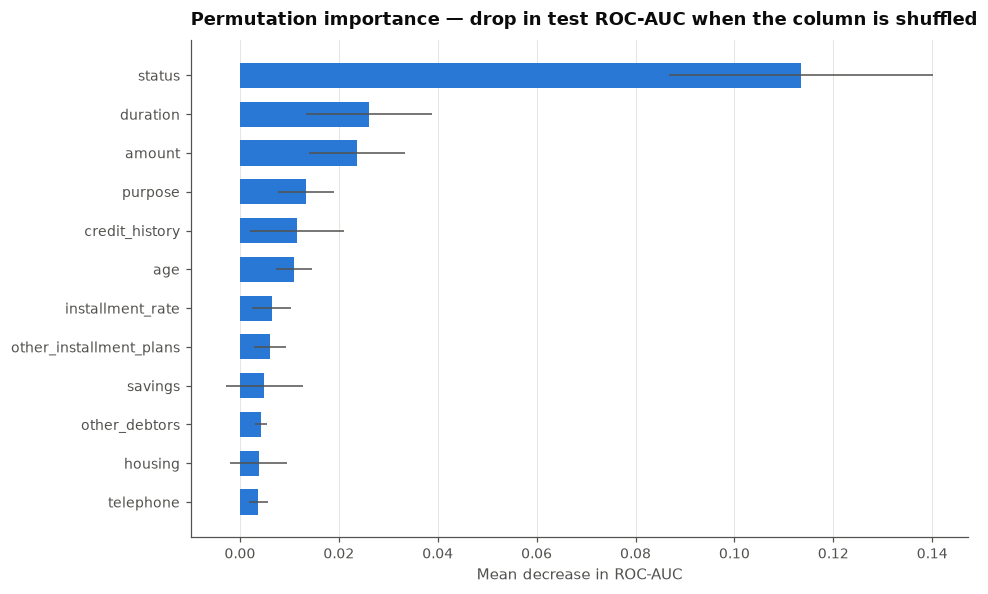

In [65]:
plot_importance = importance_table.head(12).sort_values("importance")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_importance["feature"], plot_importance["importance"],
        xerr=plot_importance["std"], color="#2a78d6", height=0.65,
        error_kw={"ecolor": "#52514e", "elinewidth": 1})
ax.set_title("Permutation importance — drop in test ROC-AUC when the column is shuffled")
ax.set_xlabel("Mean decrease in ROC-AUC")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### Cross-validation

A single train/test split on 1,000 rows is noisy — change the random seed and
the AUC moves. Cross-validation fits the model $k$ times on different splits
and reports the spread, which is a far more honest summary.

In [66]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("5-fold cross-validated ROC-AUC (mean ± SD across folds)\n")
for name, pipeline in fitted.items():
    scores = cross_val_score(pipeline, X, y, cv=folds, scoring="roc_auc")
    print(f"  {name:<26} {scores.mean():.3f} ± {scores.std():.3f}"
          f"   folds: {np.round(scores, 3)}")

5-fold cross-validated ROC-AUC (mean ± SD across folds)

  Logistic regression        0.778 ± 0.019   folds: [0.776 0.744 0.781 0.8   0.789]
  Decision tree (depth 4)    0.715 ± 0.035   folds: [0.738 0.659 0.693 0.756 0.728]
  Random forest              0.787 ± 0.037   folds: [0.809 0.749 0.763 0.849 0.764]
  Gradient boosting          0.782 ± 0.026   folds: [0.789 0.745 0.776 0.827 0.774]


The fold-to-fold spread is often larger than the difference between models.
When that is true, claiming one model is better than another is not supported
by the data — and saying so out loud is a mark of competence, not weakness.

## 10. Choosing the cut-off from money, not from 0.5

`predict()` uses a 0.5 probability threshold. There is nothing special about
0.5 — it is a default, and it is almost always the wrong business choice,
because the two errors do not cost the same.

Set up the economics explicitly:

- **Approve, borrower repays**: the bank earns a margin on the loan.
- **Approve, borrower defaults**: the bank loses loss-given-default times the
  exposure.
- **Decline**: nothing gained, nothing lost.

Write $A$ for the loan amount, $M$ for the margin earned over the life of a
performing loan, $L$ for loss given default, and $p$ for the model's
predicted probability of default. Approving is worth taking if

$$(1-p)\,M A \;-\; p\,L A \;>\; 0 \qquad\Longleftrightarrow\qquad p \;<\; \frac{M}{M+L}$$

Two things fall out of that. First, the optimal cut-off has a closed form —
you do not have to search for it. Second, the loan amount $A$ **cancels**, so
under these assumptions the same threshold applies to every loan regardless
of size. (Add a fixed origination cost and it stops cancelling, which is
Exercise 4.)

We will compute the curve numerically anyway and check that it agrees.

In [67]:
MARGIN = 0.25              # interest earned over the life of a performing loan
LOSS_GIVEN_DEFAULT = 0.60  # share of principal lost when it does not

theoretical_threshold = MARGIN / (MARGIN + LOSS_GIVEN_DEFAULT)
print(f"Closed-form optimal cut-off: {theoretical_threshold:.3f}")

exposure = X_test["amount"].to_numpy()
actually_defaulted = y_test.to_numpy()

def expected_profit(probabilities, threshold):
    """Total profit if we approve every application scored below `threshold`."""
    approve = probabilities < threshold
    profit = np.where(
        actually_defaulted == 1,
        -LOSS_GIVEN_DEFAULT * exposure,
        MARGIN * exposure,
    )
    return profit[approve].sum()


thresholds = np.linspace(0.02, 0.98, 200)
profit_curve = np.array([expected_profit(y_proba, t) for t in thresholds])

best_index = profit_curve.argmax()
best_threshold = thresholds[best_index]

approve_all = expected_profit(y_proba, 1.01)
at_half = expected_profit(y_proba, 0.5)

print(f"Approve every application:                 {approve_all:>12,.0f} DM")
print(f"Model with the default 0.5 cut-off:        {at_half:>12,.0f} DM")
print(f"Model at the best cut-off found ({best_threshold:.2f}):      {profit_curve[best_index]:>12,.0f} DM")
print(f"\nImprovement over approving everyone:       {profit_curve[best_index] - approve_all:>12,.0f} DM")
print(f"\nGrid search found {best_threshold:.3f}; the formula says {theoretical_threshold:.3f}.")
print("They agree to within the resolution of the grid, which is the point:")
print("the economics determine the cut-off, not the model.")

Closed-form optimal cut-off: 0.294
Approve every application:                      -69,127 DM
Model with the default 0.5 cut-off:              35,885 DM
Model at the best cut-off found (0.35):            65,556 DM

Improvement over approving everyone:            134,682 DM

Grid search found 0.353; the formula says 0.294.
They agree to within the resolution of the grid, which is the point:
the economics determine the cut-off, not the model.


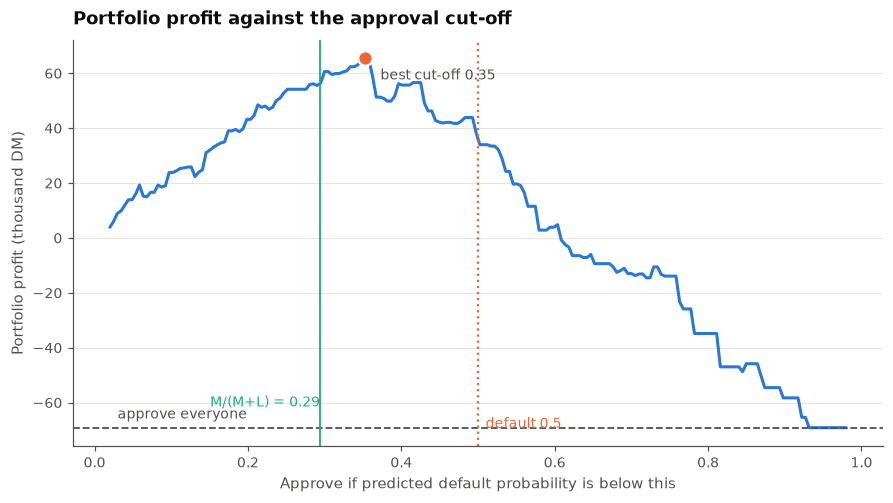

In [68]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(thresholds, profit_curve / 1000, color="#2a78d6", linewidth=2)
ax.axhline(approve_all / 1000, color="#52514e", linestyle="--", linewidth=1.2)
ax.axvline(0.5, color="#eb6834", linestyle=":", linewidth=1.5)
ax.axvline(theoretical_threshold, color="#1baf7a", linestyle="-", linewidth=1.2)
ax.scatter([best_threshold], [profit_curve[best_index] / 1000], s=90, color="#eb6834",
           zorder=5, edgecolor="white", linewidth=1.5)

ax.annotate(f"best cut-off {best_threshold:.2f}",
            xy=(best_threshold, profit_curve[best_index] / 1000),
            xytext=(10, -14), textcoords="offset points", fontsize=9, color="#52514e")
ax.annotate("approve everyone", xy=(0.03, approve_all / 1000), xytext=(0, 6),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.annotate("default 0.5", xy=(0.5, ax.get_ylim()[0]), xytext=(5, 12),
            textcoords="offset points", fontsize=9, color="#eb6834")
ax.annotate(f"M/(M+L) = {theoretical_threshold:.2f}",
            xy=(theoretical_threshold, ax.get_ylim()[0]), xytext=(-72, 26),
            textcoords="offset points", fontsize=9, color="#1baf7a")

ax.set_title("Portfolio profit against the approval cut-off")
ax.set_xlabel("Approve if predicted default probability is below this")
ax.set_ylabel("Portfolio profit (thousand DM)")
plt.show()

In [69]:
# What does the confusion matrix look like at the chosen cut-off?
y_pred_tuned = (y_proba >= best_threshold).astype(int)
tuned = confusion_matrix(y_test, y_pred_tuned)

print(f"At the 0.5 cut-off:                recall on defaults "
      f"{matrix[1, 1] / matrix[1].sum():.1%}, approvals {(y_proba < 0.5).sum()}")
print(f"At the {best_threshold:.2f} cut-off:               recall on defaults "
      f"{tuned[1, 1] / tuned[1].sum():.1%}, approvals {(y_proba < best_threshold).sum()}")
print("\nThe tuned model declines more applications and catches more bad loans.")
print("Same model, same coefficients — only the cut-off changed.")

At the 0.5 cut-off:                recall on defaults 53.3%, approvals 189
At the 0.35 cut-off:               recall on defaults 74.7%, approvals 156

The tuned model declines more applications and catches more bad loans.
Same model, same coefficients — only the cut-off changed.


This is the single most practically useful idea in the notebook. Students
spend weeks tuning hyperparameters for a hundredth of an AUC point; moving the
threshold to match the actual cost of each error is usually worth far more.

It is also where **prescriptive** analytics begins, in Duran's taxonomy. The
model produces a probability; the business rule turns it into a decision.

### Exercise 2

Rerun the profit analysis with `LOSS_GIVEN_DEFAULT = 0.35` — a secured loan
with collateral to recover. Predict which way the optimal cut-off moves
*before* you run it, using the formula, then confirm it numerically. Does the
direction match your intuition about secured versus unsecured lending?

In [70]:
old_lgd = LOSS_GIVEN_DEFAULT
LOSS_GIVEN_DEFAULT = 0.35

new_theoretical = MARGIN / (MARGIN + LOSS_GIVEN_DEFAULT)
new_profit_curve = np.array([expected_profit(y_proba, t) for t in thresholds])
new_best_threshold = thresholds[new_profit_curve.argmax()]

print(f"Closed-form cut-off with LGD = 0.35: {new_theoretical:.3f}")
print(f"Grid search cut-off:                 {new_best_threshold:.3f}")
print(f"Best profit: {new_profit_curve.max():,.0f} DM")

LOSS_GIVEN_DEFAULT = old_lgd  # put it back so later cells still use 0.60

Closed-form cut-off with LGD = 0.35: 0.417
Grid search cut-off:                 0.358
Best profit: 77,801 DM


**Exercise 2 answer:** I predicted the cut-off would go up, since M / (M + L) gets bigger when the loss on a default shrinks, and the numbers agree. The formula moves from 0.294 to 0.417, and the grid search moves from 0.353 to 0.358. The grid barely budges because the profit curve is fairly flat with only 250 test loans, but the direction matches, and best profit rises from about 65,556 DM to 77,801 DM. This fits my intuition about secured lending: when collateral lets the bank recover more of a bad loan, it can afford to approve riskier applicants.

### Exercise 3

The bank wants a scorecard it can put in front of a regulator. Fit a decision
tree with `max_depth=3`, print the rules with
`sklearn.tree.export_text(...)`, and write the top three rules out in plain
English as underwriting criteria. Then say what you gave up in AUC to get
that explainability.

In [71]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_auc_score

tree3 = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
    ]
)
tree3.fit(X_train, y_train)

names = list(tree3.named_steps["preprocess"].get_feature_names_out())
print(export_text(tree3.named_steps["model"], feature_names=names))

auc_tree = roc_auc_score(y_test, tree3.predict_proba(X_test)[:, 1])
auc_log = roc_auc_score(y_test, logistic.predict_proba(X_test)[:, 1])
print(f"ROC-AUC, depth-3 tree:        {auc_tree:.3f}")
print(f"ROC-AUC, logistic regression: {auc_log:.3f}")


|--- categorical__status_no checking account <= 0.50
|   |--- numeric__duration <= -0.78
|   |   |--- categorical__purpose_retraining <= 0.50
|   |   |   |--- class: 0
|   |   |--- categorical__purpose_retraining >  0.50
|   |   |   |--- class: 1
|   |--- numeric__duration >  -0.78
|   |   |--- categorical__savings_unknown/no savings account <= 0.50
|   |   |   |--- class: 0
|   |   |--- categorical__savings_unknown/no savings account >  0.50
|   |   |   |--- class: 0
|--- categorical__status_no checking account >  0.50
|   |--- categorical__other_installment_plans_none <= 0.50
|   |   |--- categorical__employment_duration_4 <= ... < 7 years <= 0.50
|   |   |   |--- class: 0
|   |   |--- categorical__employment_duration_4 <= ... < 7 years >  0.50
|   |   |   |--- class: 0
|   |--- categorical__other_installment_plans_none >  0.50
|   |   |--- categorical__credit_history_delay in paying off in the past <= 0.50
|   |   |   |--- class: 0
|   |   |--- categorical__credit_history_delay in p

**Exercise 3 answer:** The tree's top three rules, as underwriting criteria, are these. First, applicants with no checking account are the safest group and get approved. Second, among applicants who do have a checking account, anyone asking for a loan longer than roughly a year is approved. Third, the only group the tree flags as likely to default is applicants with a checking account who want a short loan (about a year or less) for retraining. Every other branch ends in approval. To get rules simple enough to show a regulator, I gave up a lot of ranking power: ROC-AUC fell from 0.800 for the logistic regression to 0.691 for the tree, a drop of about 0.11.

### Exercise 4

Add a fixed origination cost of 150 DM to every approved loan, regardless of
size. Re-derive the approval rule on paper: the loan amount no longer
cancels, so the cut-off now depends on $A$. Implement it — approve when
$(1-p)MA - pLA - 150 > 0$ — and compare total portfolio profit against the
single-threshold rule. Which loans does the new rule decline that the old one
approved?

In [72]:
ORIGINATION_COST = 150
proba = np.asarray(y_proba)

# Profit if every loan in `approve` is made, with the fixed 150 DM cost on each
def portfolio_profit(approve):
    per_loan = np.where(actually_defaulted == 1,
                        -LOSS_GIVEN_DEFAULT * exposure,
                        MARGIN * exposure) - ORIGINATION_COST
    return per_loan[approve].sum()

# Old rule: one cut-off for everyone
old_approve = proba < best_threshold

# New rule: approve when (1 - p) * M * A - p * L * A - 150 > 0
expected_gain = ((1 - proba) * MARGIN * exposure
                 - proba * LOSS_GIVEN_DEFAULT * exposure
                 - ORIGINATION_COST)
new_approve = expected_gain > 0

print(f"Old single-threshold rule: {portfolio_profit(old_approve):>10,.0f} DM ({old_approve.sum()} approvals)")
print(f"New amount-aware rule:     {portfolio_profit(new_approve):>10,.0f} DM ({new_approve.sum()} approvals)")

declined = old_approve & ~new_approve
print(f"\nApproved by the old rule but declined by the new one: {declined.sum()} loans")
print(f"Average amount of those loans:         {exposure[declined].mean():,.0f} DM")
print(f"Average amount of all old approvals:   {exposure[old_approve].mean():,.0f} DM")

Old single-threshold rule:     42,156 DM (156 approvals)
New amount-aware rule:         36,514 DM (109 approvals)

Approved by the old rule but declined by the new one: 47 loans
Average amount of those loans:         1,970 DM
Average amount of all old approvals:   2,743 DM


**Exercise 4 answer:** With the 150 DM fixed cost, the new rule approves 109 loans instead of 156 and earns 36,514 DM compared with 42,156 DM for the single-threshold rule, so on this test set it actually did a bit worse. That isn't a contradiction, because the old cut-off was found by searching these same 250 test outcomes, so it is tuned to this sample, while the new rule comes straight from the formula. The 47 loans it declines tend to be smaller, averaging 1,970 DM versus 2,743 DM for all the old approvals, which makes sense because a fixed 150 DM cost eats a bigger share of the profit on a small loan.

---

## Recap

1. Explore before you model; category-level default rates carry most of the
   story.
2. Some predictive variables are unlawful to use. Dropping them is necessary
   and not sufficient.
3. Put preprocessing inside a `Pipeline` so leakage becomes impossible rather
   than merely discouraged.
4. Accuracy is close to useless on imbalanced data. Use ROC-AUC, precision,
   recall, and look at the confusion matrix.
5. Logistic regression is still the default in regulated lending because a
   coefficient is an explanation.
6. A training-test accuracy gap is overfitting.
7. Cross-validate; if the fold spread exceeds the gap between models, you do
   not have a winner.
8. Set the cut-off from expected profit, not from 0.5. Under simple
   assumptions it is just $M/(M+L)$.

Next: `05_ml_market_prediction.ipynb` — the same machinery, applied to a
problem where the signal is much weaker, and what to do about that.